In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## Dataset 1: Pakistani E-Commerce Data (`pakistani_ecommerce_dataset.csv`)

In [6]:
df = pd.read_csv(r"C:\Users\Aliyan\Downloads\pakistani_ecommerce_dataset.csv")
df.head(5)

,user_id,gender,age_group,city,product_category,payment_method,order_value,order_status
0,U001,Male,25-34,Islamabad,Home Decor,JazzCash,1899.62,Pending
1,U002,Female,25-34,Lahore,Electronics,EasyPaisa,1592.21,Cancelled
2,U003,Female,25-34,Lahore,Books,Debit Card,3851.78,Cancelled
3,U004,Female,18-24,Lahore,Home Decor,Cash on Delivery,1774.12,Pending
4,U005,Female,35-44,Lahore,Home Decor,EasyPaisa,3611.28,Cancelled


In [7]:
# Q1: Which is the most popular product category?
cat_counts = df['product_category'].value_counts()
print('--- Q1: Orders by Product Category ---')
print(cat_counts)
print(f'Answer Q1 -> Most popular product category: {cat_counts.idxmax()} ({cat_counts.max()} orders)\n')

# Q2: What is the average order value?
avg_order = df['order_value'].mean()
med_order = df['order_value'].median()
print('--- Q2: Average Order Value ---')
print(f'Answer Q2 -> Average order value: PKR {avg_order:,.2f} (Median: PKR {med_order:,.2f})\n')

# Q3: Which city has the highest number of orders?
city_counts = df['city'].value_counts()
print('--- Q3: Orders by City ---')
print(city_counts)
print(f'Answer Q3 -> City with highest number of orders: {city_counts.idxmax()} ({city_counts.max()} orders)\n')

# Q4: What is the most used payment method?
pay_counts = df['payment_method'].value_counts()
print('--- Q4: Payment Method Usage ---')
print(pay_counts)
print(f'Answer Q4 -> Most used payment method: {pay_counts.idxmax()} ({pay_counts.max()} orders)')

--- Q1: Orders by Product Category ---
product_category
Home Decor     30
Clothing       22
Beauty         19
Electronics    18
Books          11
Name: count, dtype: int64
Answer Q1 -> Most popular product category: Home Decor (30 orders)

--- Q2: Average Order Value ---
Answer Q2 -> Average order value: PKR 2,832.15 (Median: PKR 2,888.28)

--- Q3: Orders by City ---
city
Karachi       24
Islamabad     21
Rawalpindi    20
Lahore        18
Faisalabad    17
Name: count, dtype: int64
Answer Q3 -> City with highest number of orders: Karachi (24 orders)

--- Q4: Payment Method Usage ---
payment_method
Cash on Delivery    29
JazzCash            27
EasyPaisa           23
Debit Card          21
Name: count, dtype: int64
Answer Q4 -> Most used payment method: Cash on Delivery (29 orders)


         city  order_value
0   Islamabad      3011.95
1     Karachi      2956.50
2  Faisalabad      2937.08
3      Lahore      2785.33
4  Rawalpindi      2447.08


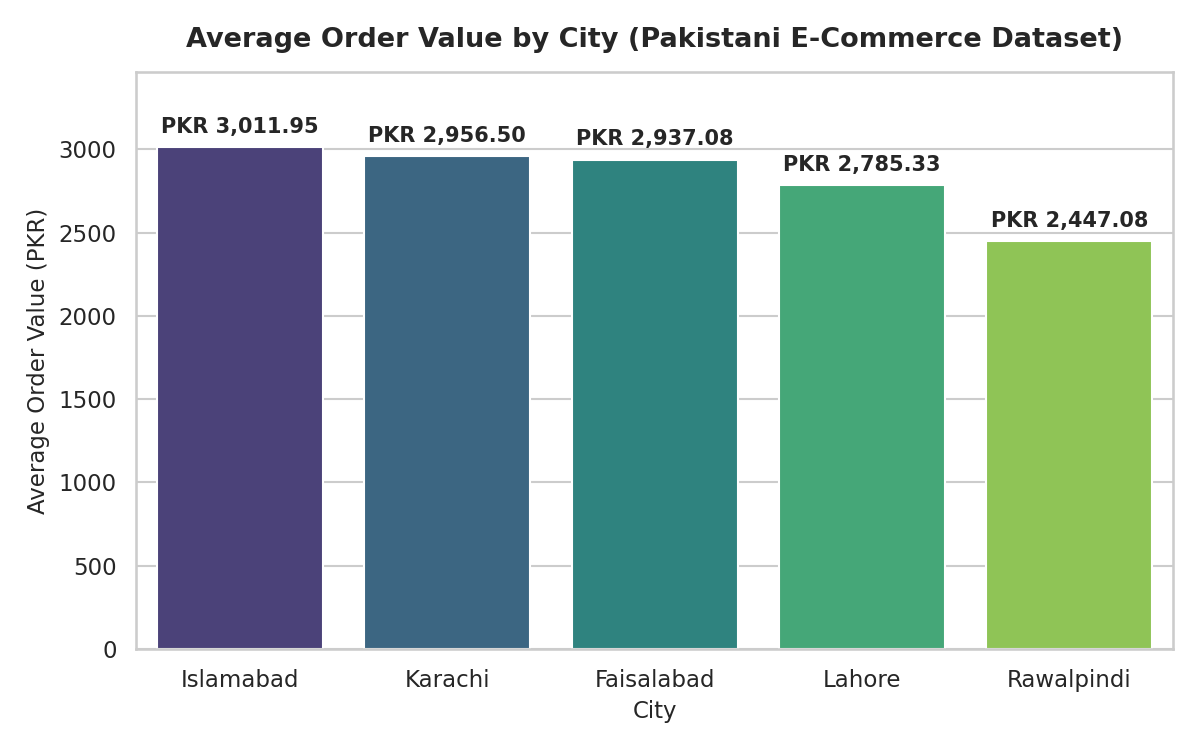

In [4]:
# Q5: Draw a bar chart showing average order value by city
city_avg = df.groupby('city')['order_value'].mean().sort_values(ascending=False).reset_index()
print(city_avg.round(2))

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=city_avg, x='city', y='order_value', palette='viridis')
ax.set_title('Average Order Value by City (Pakistani E-Commerce Dataset)', fontsize=13, fontweight='bold')
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel('Average Order Value (PKR)', fontsize=11)
ax.set_ylim(0, city_avg['order_value'].max() * 1.15)

for bar in ax.patches:
    h = bar.get_height()
    ax.annotate(f'PKR {h:,.2f}', (bar.get_x() + bar.get_width() / 2, h),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

---
## Dataset 2: Student Lifestyle & Study Habits (`student_lifestyle_dataset.csv`)

In [8]:
# Load Dataset 2
df_student = pd.read_csv(r"C:\Users\Aliyan\Downloads\student_lifestyle_dataset.csv")
df_student.head(5)

,user_id,gender,age_group,city,product_category,payment_method,order_value,order_status
0,U001,Male,25-34,Islamabad,Home Decor,JazzCash,1899.62,Pending
1,U002,Female,25-34,Lahore,Electronics,EasyPaisa,1592.21,Cancelled
2,U003,Female,25-34,Lahore,Books,Debit Card,3851.78,Cancelled
3,U004,Female,18-24,Lahore,Home Decor,Cash on Delivery,1774.12,Pending
4,U005,Female,35-44,Lahore,Home Decor,EasyPaisa,3611.28,Cancelled


In [9]:
# Q1: What is the average number of study hours?
avg_study = df_student['study_hours'].mean()
med_study = df_student['study_hours'].median()
print('--- Q1: Average Study Hours ---')
print(f'Answer Q1 -> Average study hours: {avg_study:.2f} hours/day (exact: {avg_study:.3f}, Median: {med_study:.2f})\n')

# Q2: Who sleeps more on average - males or females?
sleep_gender = df_student.groupby('gender')['sleep_hours'].mean()
print('--- Q2: Average Sleep Hours by Gender ---')
print(sleep_gender.round(4))
print(f"Answer Q2 -> Females sleep more on average ({sleep_gender['Female']:.2f} hrs vs. {sleep_gender['Male']:.2f} hrs for males; difference = +{sleep_gender['Female'] - sleep_gender['Male']:.2f} hrs)\n")

# Q3: Is there a relationship between screen time and sleep hours?
corr_screen_sleep = df_student['screen_time'].corr(df_student['sleep_hours'])
print('--- Q3: Correlation between Screen Time and Sleep Hours ---')
print(f'Answer Q3 -> Pearson correlation r = {corr_screen_sleep:.4f} (no meaningful linear relationship)\n')

# Q5: Compare average internet usage by gender
net_gender = df_student.groupby('gender')['internet_usage'].mean()
print('--- Q5: Average Internet Usage by Gender ---')
print(net_gender.round(4))
print(f"Answer Q5 -> Males use internet more on average ({net_gender['Male']:.2f} hrs/day vs. {net_gender['Female']:.2f} hrs/day for females; difference = +{net_gender['Male'] - net_gender['Female']:.2f} hrs/day)")

--- Q1: Average Study Hours ---
Answer Q1 -> Average study hours: 4.40 hours/day (exact: 4.403, Median: 4.30)

--- Q2: Average Sleep Hours by Gender ---
gender
Female    6.7962
Male      6.3896
Name: sleep_hours, dtype: float64
Answer Q2 -> Females sleep more on average (6.80 hrs vs. 6.39 hrs for males; difference = +0.41 hrs)

--- Q3: Correlation between Screen Time and Sleep Hours ---
Answer Q3 -> Pearson correlation r = 0.0524 (no meaningful linear relationship)

--- Q5: Average Internet Usage by Gender ---
gender
Female    5.3212
Male      6.0021
Name: internet_usage, dtype: float64
Answer Q5 -> Males use internet more on average (6.00 hrs/day vs. 5.32 hrs/day for females; difference = +0.68 hrs/day)


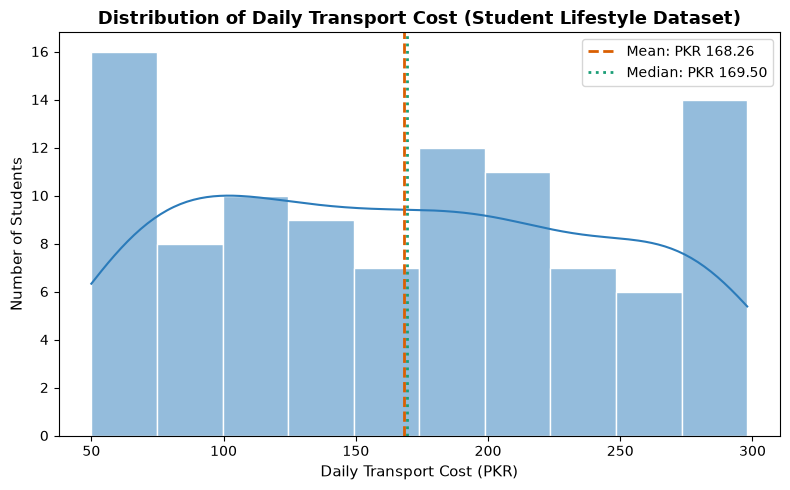

In [10]:
# Q4: Draw a histogram of daily transport cost
plt.figure(figsize=(8, 5))
ax = sns.histplot(data=df_student, x='daily_transport_cost', bins=10, kde=True, color='#2b7bba', edgecolor='white')
ax.axvline(df_student['daily_transport_cost'].mean(), color='#d95f02', linestyle='--', linewidth=2,
           label=f"Mean: PKR {df_student['daily_transport_cost'].mean():.2f}")
ax.axvline(df_student['daily_transport_cost'].median(), color='#1b9e77', linestyle=':', linewidth=2,
           label=f"Median: PKR {df_student['daily_transport_cost'].median():.2f}")
ax.set_title('Distribution of Daily Transport Cost (Student Lifestyle Dataset)', fontsize=13, fontweight='bold')
ax.set_xlabel('Daily Transport Cost (PKR)', fontsize=11)
ax.set_ylabel('Number of Students', fontsize=11)
ax.legend()
plt.tight_layout()
plt.show()